In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
from scipy.integrate import odeint
from scipy.linalg import solve_continuous_lyapunov

In [2]:
def covariance_modes(covariances):
    C=np.asarray(covariances,float)
    n,p=C.shape[:2]
    vals=np.full((n,p),np.nan);vectors=np.full((n,p),np.nan)
    finite=np.isfinite(C).all(axis=(1,2))
    if finite.any():
        lam,V=np.linalg.eigh((C[finite]+C[finite].transpose(0,2,1))/2)
        vals[finite]=np.maximum(lam,0);vectors[finite]=V[:,:,-1]
    leading=vals[:,-1];norm=np.linalg.norm(vals,axis=1)
    q=np.divide(leading,norm,out=np.full(n,np.nan),where=norm>0)
    vectors[leading==0]=np.nan
    angle=np.full(n,np.nan)
    if n>1:
        cosine=np.abs(np.einsum("ti,ti->t",vectors[:-1],vectors[1:]))
        angle[1:]=np.arccos(np.clip(cosine,0,1))
    return {"lambda1":leading,"normalised_l2":q,"gap":leading-vals[:,-2],
            "vector":vectors,"angle":angle}

In [ ]:
def symmetric_matrix(theta):
    theta = np.asarray(theta, dtype=float).ravel()
    n = int((np.sqrt(1 + 8 * theta.size) - 1) / 2)
    matrix = np.zeros((n, n))
    matrix[np.triu_indices(n)] = theta
    return matrix + matrix.T - np.diag(np.diag(matrix))


def extract_theta(matrix):
    matrix = np.asarray(matrix, dtype=float)
    return matrix[np.triu_indices(matrix.shape[0])].copy()


def covariance_summary(covariance):
    covariance = np.asarray(covariance, dtype=float)
    shape = covariance.shape[:-2]
    k = covariance.shape[-1]
    flat = covariance.reshape(-1, k, k)
    eigenvalues = np.full((len(flat), k), np.nan)
    vectors = np.full((len(flat), k), np.nan)
    finite = np.isfinite(flat).all(axis=(1, 2))
    if finite.any():
        vals, vecs = np.linalg.eigh(0.5 * (flat[finite] + flat[finite].transpose(0, 2, 1)))
        vals = np.maximum(vals, 0.0)
        eigenvalues[finite] = vals
        vectors[finite] = vecs[:, :, -1]
    norm = np.linalg.norm(eigenvalues, axis=1)
    ratio = np.full(len(flat), np.nan)
    np.divide(eigenvalues[:, -1], norm, out=ratio, where=norm > 0)
    vectors[norm == 0] = np.nan
    return {
        "eigenvalues": eigenvalues.reshape(*shape, k),
        "lambda1": eigenvalues[:, -1].reshape(shape),
        "normalised": ratio.reshape(shape),
        "eigenvector": vectors.reshape(*shape, k),
    }


def covariance_to_correlation(covariance):
    covariance = np.asarray(covariance, dtype=float)
    diagonal = np.diagonal(covariance, axis1=-2, axis2=-1)
    standard_deviation = np.sqrt(np.maximum(diagonal, 0.0))
    denominator = standard_deviation[..., :, None] * standard_deviation[..., None, :]
    correlation = np.full_like(covariance, np.nan)
    np.divide(covariance, denominator, out=correlation, where=denominator > 0)
    return correlation


def ensemble_covariance(runs, population):
    residual = (runs - runs.mean(axis=0, keepdims=True)) / np.sqrt(population)
    return np.einsum("rct,rdt->tcd", residual, residual) / (len(runs) - 1)

def interpolate_series(times, values, new_times):
    """Interpolate on the final time axis, with no extrapolation."""
    times, new_times = np.asarray(times), np.asarray(new_times)
    tol = 1e-9 * max(1.0, np.ptp(times))
    target = np.clip(new_times, times[0], times[-1])
    flat = np.asarray(values).reshape(-1, len(times))
    out = np.array([np.interp(target, times, row) for row in flat])
    return out.reshape(*np.shape(values)[:-1], len(target))


def crossing_times(times, values, level=0.0):
    times, values = np.asarray(times), np.asarray(values) - level
    roots = list(times[np.isclose(values, 0.0, atol=1e-12, rtol=0.0)])
    for i in np.flatnonzero(values[:-1] * values[1:] < 0):
        roots.append(times[i] - values[i] * (times[i + 1] - times[i]) / (values[i + 1] - values[i]))
    return np.unique(np.round(roots, 12))

In [5]:
def jacobian_and_diffusion(S_counts, I_counts, beta, gamma, mu, population):
    s = np.asarray(S_counts, dtype=float) / population
    i = np.asarray(I_counts, dtype=float) / population
    beta = np.asarray(beta, dtype=float)
    force = beta @ i
    infection = s * force
    J_ss = np.diag(-mu - force)
    J_si = -s[:, None] * beta
    J_is = np.diag(force)
    J_ii = s[:, None] * beta - (gamma + mu) * np.eye(3)
    J = np.block([[J_ss, J_si], [J_is, J_ii]])

    B_ss = np.diag(mu * (1 - s) + infection)
    B_si = np.diag(-mu * i - infection)
    B_ii = np.diag((gamma + mu) * i + infection)
    B = np.block([[B_ss, B_si], [B_si.T, B_ii]])
    return J, B


def meta_int(X, t, betat, gamma, mu, Na):
    S, I, theta = X[:3], X[3:6], X[6:]
    beta = np.asarray(betat(t), dtype=float)
    force = (beta @ I) / Na
    dS = -force * S + (Na - S) * mu
    dI = force * S - (gamma + mu) * I
    J, B = jacobian_and_diffusion(S, I, beta, gamma, mu, Na)
    covariance = symmetric_matrix(theta)
    derivative = J @ covariance + covariance @ J.T + B
    return np.concatenate([dS, dI, extract_theta(derivative)])

$R_0=1/(\gamma+\mu)*\rho(\beta)$

In [6]:
# system parameters
gamma = 0.1
mu = 1/(80*365)
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
np.max(np.linalg.eigvals(beta_matrix))/(gamma+mu)

4.005684465099393

## Constant $R_t$

In [16]:
def meta_int_null(X, t, beta0, gamma, mu, Na):
    S, I, theta = X[:3], X[3:6], X[6:]
    K0 = S[:, None] * beta0(t) / (gamma + mu)
    current_Rt = np.max(np.abs(np.linalg.eigvals(K0)))

    beta = beta0(t) * 1 / current_Rt
    beta = np.asarray(betat(t), dtype=float)
    force = (beta @ I) / Na
    dS = -force * S + (Na - S) * mu
    dI = force * S - (gamma + mu) * I
    J, B = jacobian_and_diffusion(S, I, beta, gamma, mu, Na)
    covariance = symmetric_matrix(theta)
    derivative = J @ covariance + covariance @ J.T + B
    return np.concatenate([dS, dI, extract_theta(derivative)])

In [45]:
def analyze_epidemic_data_null(folder_name, betat, ts, gamma, mu, N_population, Si, Ii, etol, R_target=100000):
    # etol is retained for compatibility; actual crossings are now interpolated.
    ts = np.asarray(ts, dtype=float)
    initial = np.r_[Si, Ii, np.zeros(21)]
    theory = odeint(meta_int_null, initial, ts, args=(betat, gamma, mu, N_population, R_target),
                    rtol=1e-8, atol=1e-10, mxstep=10000)
    full_covariance = np.array([symmetric_matrix(row[6:]) for row in theory])
    covariance = full_covariance[:, 3:, 3:]
    summary = covariance_summary(covariance)

    result = {
        "scenario": folder_name, "times": ts, "population": N_population,
        "gamma": gamma, "mu": mu,
        "theory": theory, "full_covariance": full_covariance,
        "covariance": covariance, "eigvals": summary["lambda1"],
        "norm_eigvals": summary["normalised"], "eigvec": summary["eigenvector"]
    }
    return result


def plot_epidemic_results_null(results, ts, npi_time=None,save_path=None, legend=True, mini_loc="center right"):
    ts = np.asarray(ts)
    n = len(ts)
    fig, axs = plt.subplots(4, 1, figsize=(10, 18), sharex=True, constrained_layout=True)
    styles = ["solid", "dashed", "dotted"]
    colors = ["#E69F00", "#56B4E9", "#009E73"]
    for city in range(3):
        axs[0].plot(ts, results["theory"][:n, city + 3], linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
        axs[2].plot(ts, np.abs(results["eigvec"][:n, city]), linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
    axs[1].plot(ts, results["eigvals"][:n], label=r"$\lambda_1$ - Theory", linewidth=2)
    ax1 = axs[1].twinx()
    ax1.plot(ts, results["norm_eigvals"][:n], label=r"$\lambda_1/\|\lambda\|_2$ - Theory", linewidth=2, color = 'k')
    comparisons=[("Eigenvalue gap - Theory",results["covariance"],"-")]
    for label,C,style in comparisons:
        modes=covariance_modes(C[:n])
        axs[3].plot(ts,modes["gap"],style,label=label)
    comparisons=[("Angular Displacement - Theory",results["covariance"],"-")]
    ax3 = axs[3].twinx()
    ax3.plot(ts,covariance_modes(results["covariance"][:n])["angle"],"-",label="Angular Displacement - Theory",color="k")
    for ax in axs:
        if npi_time is not None and ts[0] <= npi_time <= ts[-1]:
            ax.axvline(npi_time, color="k", alpha=0.6)
        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=12)
    labels = ["Number infectious", r"$R_t$", r"$\lambda_1$",
              r"$\lambda_1/\|\lambda\|_2$", "Absolute dominant eigenvector",
              r"Covariance gap $\lambda_1-\lambda_2$", "Eigenvector rotation (rad)"]
    axs_label = [axs[0], axs[1], ax1, axs[2], axs[3], ax3]
    for ax, label in zip(axs_label, labels):
        ax.set_ylabel(label, fontsize=13)
    axs[0].set_ylim(bottom=0)
    axs[1].set_ylim(bottom=0)
    axs[2].set_ylim(bottom=0)
    ax1.set_ylim(0, 1.05)
    axs[2].set_ylim(0, 1.05)
    axs[-1].set_xlabel("Time (days)")
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [49]:
def meta_int_null(X, t, beta0, gamma, mu, Na, Rt_target=100000.0):
    S, I, theta = X[:3], X[3:6], X[6:]
    K0 = S[:, None] * beta0(t) / (gamma + mu)
    current_Rt = np.max(np.abs(np.linalg.eigvals(K0)))
    #print(current_Rt)

    beta = beta0(t) * Rt_target / current_Rt
    K0 = S[:, None] * beta / (gamma + mu)
    current_Rt = np.max(np.abs(np.linalg.eigvals(K0)))
    #print(current_Rt)
    force = (beta @ I) / Na
    dS = -force * S + (Na - S) * mu
    dI = force * S - (gamma + mu) * I
    J, B = jacobian_and_diffusion(S, I, beta, gamma, mu, Na)
    covariance = symmetric_matrix(theta)
    derivative = J @ covariance + covariance @ J.T + B
    return np.concatenate([dS, dI, extract_theta(derivative)])

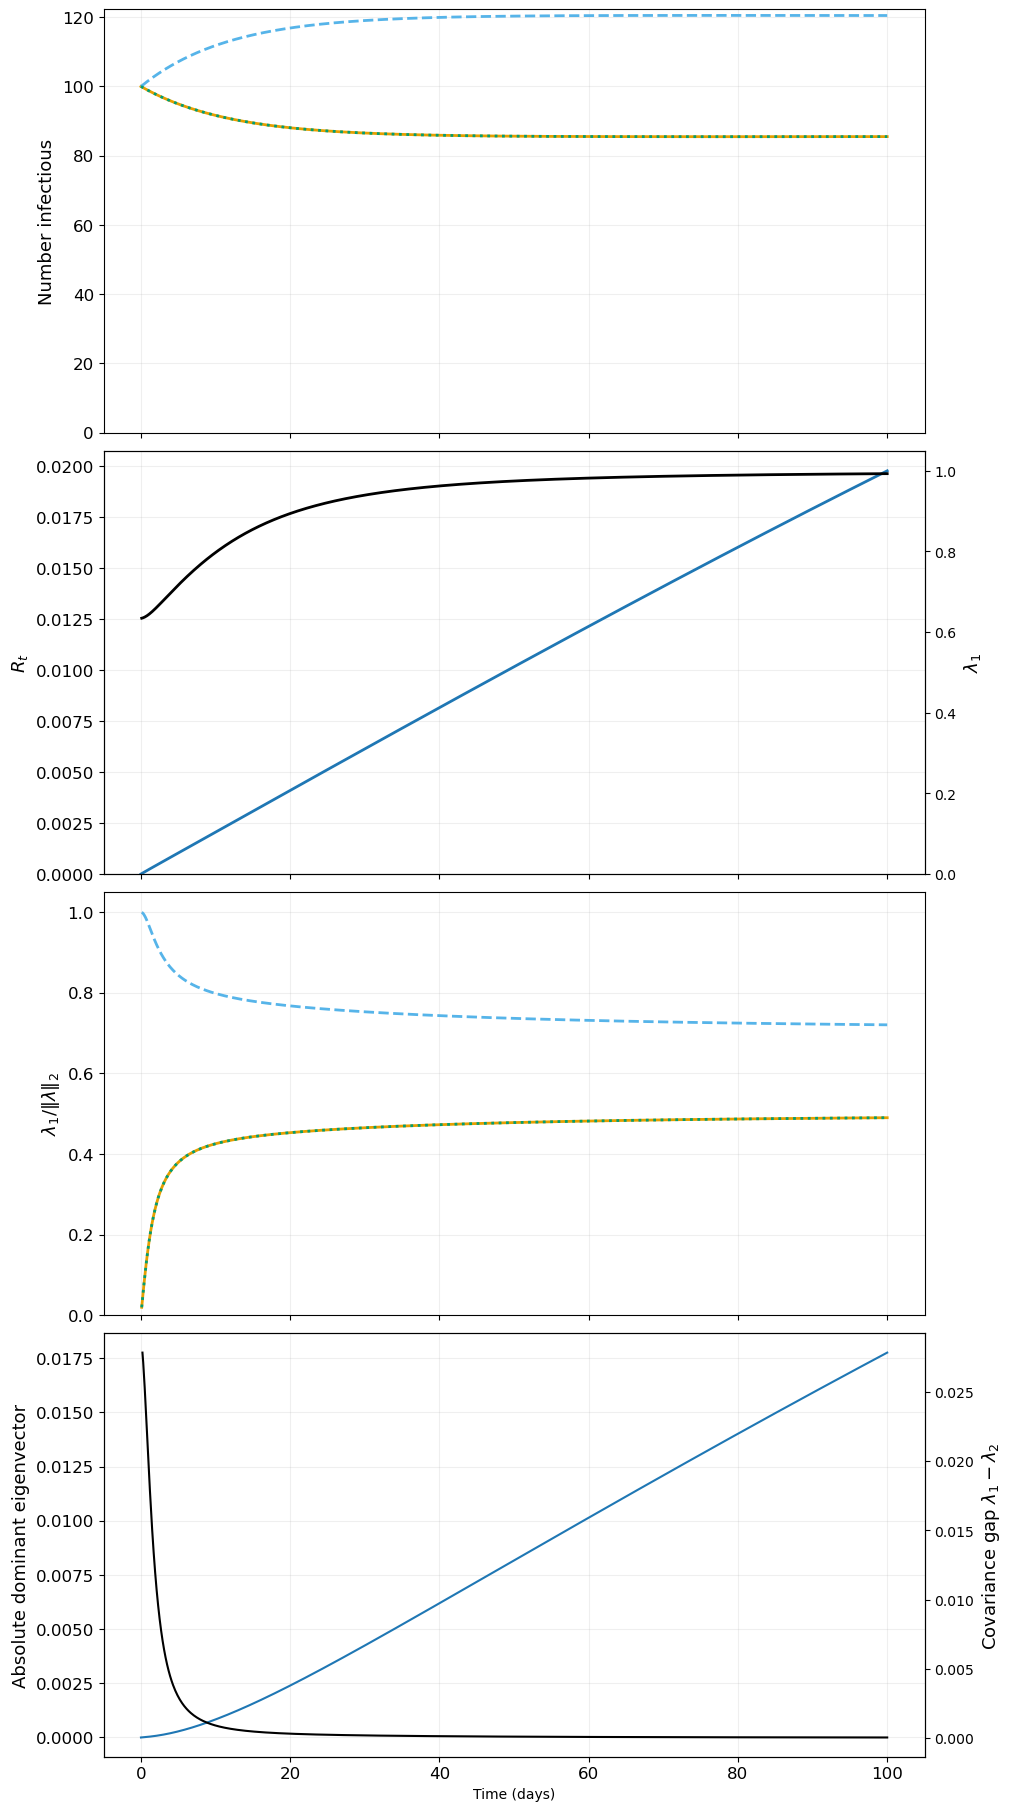

In [ ]:
# parameters
N_cities = 3
T_max = 100
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
gamma = 0.1
mu = 1/(80*365)
N_population = 100000

Ii = np.array([100,100,100])
Si = N_population - Ii

betat = lambda t: beta_matrix
days = np.arange(0,101,1)
ts = np.arange(0,100.1,0.1)
results_null = analyze_epidemic_data_null('constant', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_null(results_null, ts, save_path = "Rev_Figures/sir_null_model.png")

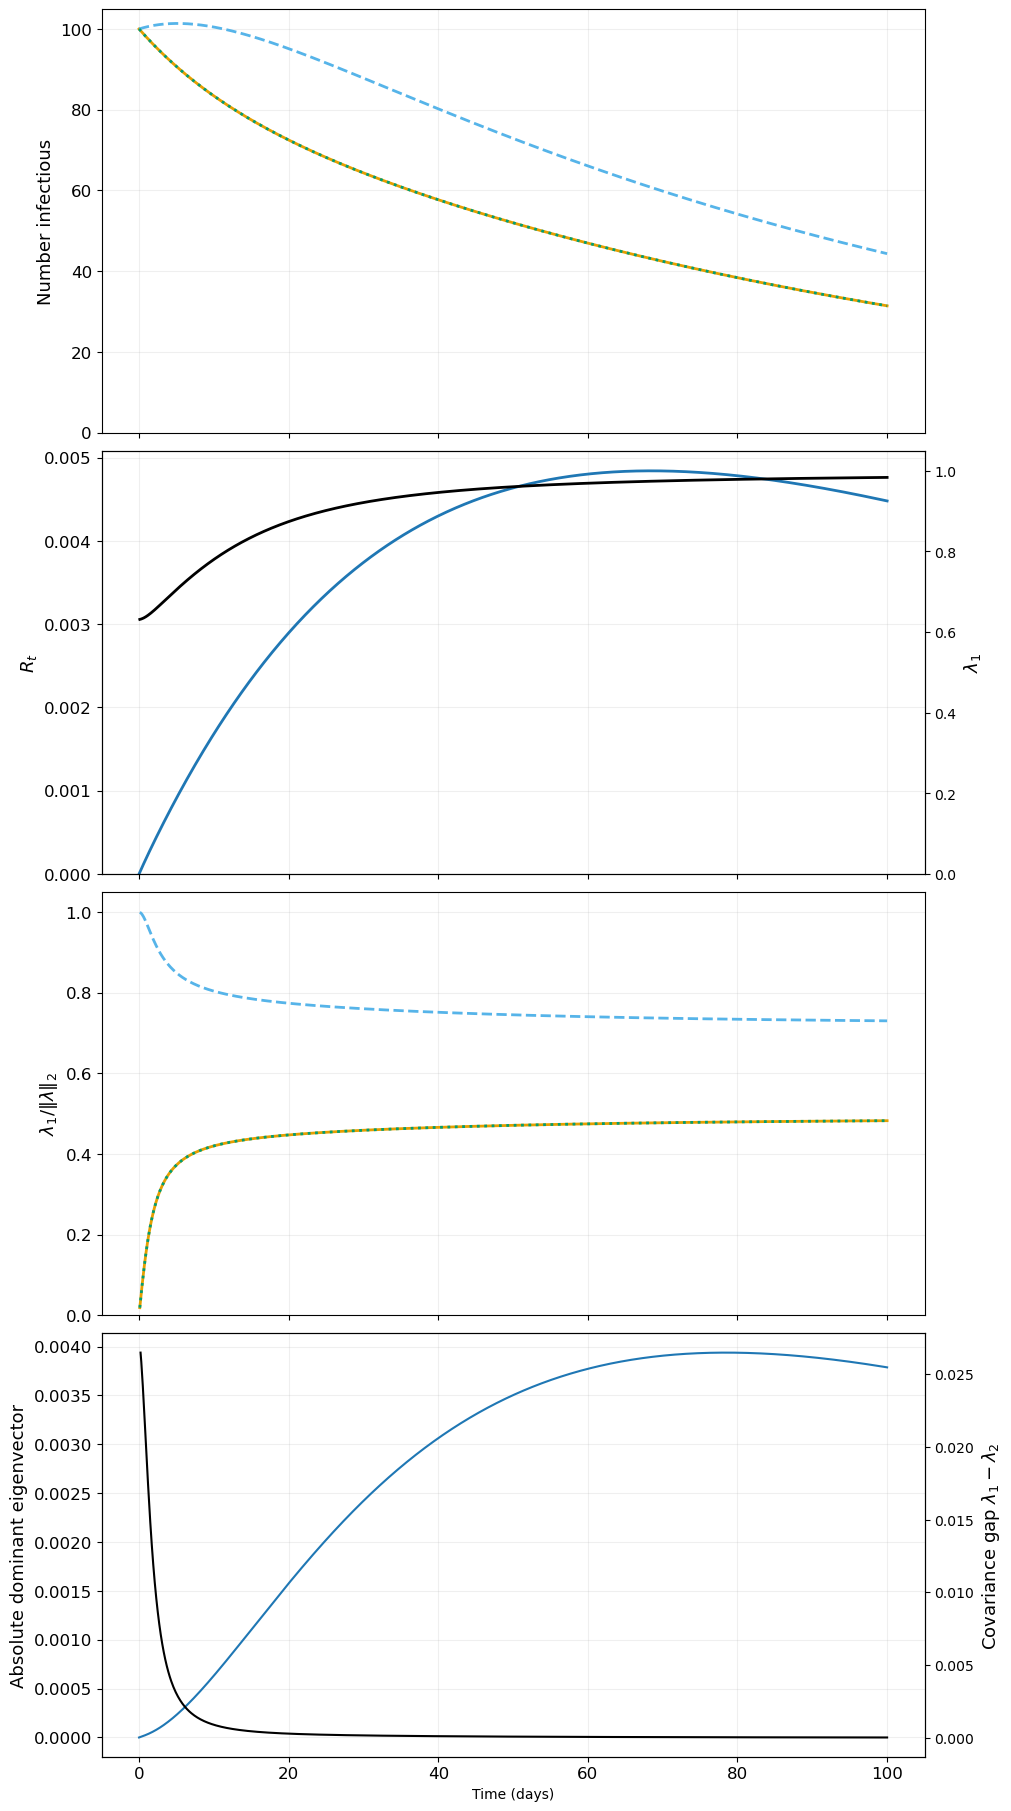

In [ ]:
results_null = analyze_epidemic_data_null('constant', betat, ts, gamma, mu, N_population, Si, Ii, 0.005, 90000)
plot_epidemic_results_null(results_null, ts, save_path = "Rev_Figures/sir_null_model_decrease.png")